# Excel dataset inventory

This notebook discovers Excel workbooks recursively under `dataset/` and reads them without changing the source files. It records workbook and worksheet failures, profiles columns, saves first/last nonempty records, and writes reports and charts to `reports/data_inventory/`.

Worksheet rows include preamble and header rows; data rows start below the inferred header. Missing counts use the data rows and treat empty or whitespace-only strings as blank. Completely empty worksheet columns include the header and preamble. Header selection is heuristic; check the reported Excel row. Year-first date text is interpreted year-month-day; other numeric date text is interpreted day-first. Month/year values use the first day of the month. Formula cells use cached values. Identifier candidates are name-based or unique within a sample of up to 10,000 nonblank values, and are not proof of uniqueness. Sample JSON arrays follow the worksheet column order.

The generated sample report can contain business data. Source files are checked with SHA-256 before and after inspection.

## Additional validation review ? 2026-10-30

Read [the inventory validation report](../reports/data_inventory/inventory_validation_report.md) and its [detailed evidence](../reports/data_inventory/validation/inventory_validation_evidence.xlsx) alongside the original outputs below.

The review includes all 17 source files: 14 Excel workbooks (17 worksheets) and 3 relevant GST CSV tables. The original date coverage and chart reflect the parsing rules stated above; ambiguous day/month strings, numeric date candidates, incomplete periods and invalid dates require the separate validated date evidence. Potential identifiers below are exploratory flags. Full-column uniqueness, nulls, duplicates and candidate matching coverage are documented in the validation evidence; no business primary key or cross-source relationship is confirmed.

The validation report supersedes unconditional interpretations of the initial date coverage and identifier flags. The code and saved outputs below retain the original Excel inventory for traceability.

In [1]:
from pathlib import Path
from collections import Counter, deque
from datetime import date, datetime, time
import hashlib
import itertools
import json
import re
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import xlrd
from dateutil import parser as date_parser
from openpyxl import load_workbook
from IPython.display import display

# The notebook may be opened from either the project root or notebooks/.
PROJECT = Path.cwd().resolve()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
DATASET = PROJECT / 'dataset'
REPORTS = PROJECT / 'reports' / 'data_inventory'
REPORTS.mkdir(parents=True, exist_ok=True)
if not DATASET.is_dir():
    raise FileNotFoundError(f'Dataset folder not found: {DATASET}')

In [2]:
# Include every file with a supported Excel extension, including files in subfolders.
excel_files = sorted(p for p in DATASET.rglob('*')
                     if p.is_file() and p.suffix.lower() in {'.xlsx', '.xlsm', '.xls'})
print(f'Discovered {len(excel_files)} Excel files.')
display(pd.DataFrame({'file': [str(p.relative_to(DATASET)) for p in excel_files]}))

def fingerprint(path):
    digest = hashlib.sha256()
    with path.open('rb') as source:
        for block in iter(lambda: source.read(1024 * 1024), b''):
            digest.update(block)
    stat = path.stat()
    return {'sha256': digest.hexdigest(), 'size_bytes': stat.st_size,
            'modified_ns': stat.st_mtime_ns}

before = {}
for path in excel_files:
    try:
        before[path] = fingerprint(path)
    except Exception as exc:
        before[path] = {'error': f'{type(exc).__name__}: {exc}'}

Discovered 14 Excel files.


,file
0,Customer Master Report 1.xlsx
1,Customer Master Report 2.xlsx
2,Exchange Rate 1.xlsx
3,Exchange Rate.xlsx
4,Inventory Audit Report as on 200327.xlsx
5,Inventory Audit Report as on 200926 1.xlsx
6,Inventory Audit Report as on 200926.xlsx
7,Item Master Lists 1.xlsx
8,Item Master Lists 2.xlsx
9,Sales Invoice Details 1.xlsx


In [3]:
# Rows are streamed so large workbooks do not need to fit in memory. Blank means
# None or an empty/whitespace-only string. Counts below the inferred header
# include blank rows; worksheet counts also include title and preamble rows.
# Formula cells are read from Excel's cached values, which may be absent.
def is_blank(value):
    return value is None or (isinstance(value, str) and not value.strip())

def data_type(value):
    if isinstance(value, bool): return 'boolean'
    if isinstance(value, datetime): return 'datetime'
    if isinstance(value, date): return 'date'
    if isinstance(value, time): return 'time'
    if isinstance(value, (int, float)): return 'number'
    if isinstance(value, str): return 'text'
    return type(value).__name__

def as_json_value(value):
    if isinstance(value, (datetime, date, time)): return value.isoformat()
    if isinstance(value, (str, int, float, bool)) or value is None: return value
    return str(value)

def header_row_index(rows):
    # Prefer rows containing many text labels and recognizable header terms.
    # The first row wins ties. This detects title/preamble rows above tables.
    if not rows: return None
    scores = []
    for row in rows:
        values = [v for v in row if not is_blank(v)]
        texts = [v for v in values if isinstance(v, str)]
        header_terms = sum(bool(re.search(r'\b(code|name|date|month|year|category|segment|quantity|price|description|customer|currency|country|item|status|number|no)\b', text, re.I)) for text in texts)
        scores.append((len(texts) + 2 * header_terms, len(texts), len(values)))
    best = max(range(len(scores)), key=lambda i: scores[i])
    return best if scores[best][2] else None

DATE_NAME = re.compile(r'\b(date|month|year|period|day)\b', re.I)
ID_NAME = re.compile(r'(^#|\b(id|code|key|number|num|no|reference|ref|sku)\b)', re.I)
DATE_STRING = re.compile(r'(\d{1,4}[./-]\d{1,2}[./-]\d{1,4}|\b(?:jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*\b)', re.I)
SAMPLE_UNIQUE_LIMIT = 10000

def parse_date(value):
    if isinstance(value, datetime): return value.replace(tzinfo=None)
    if isinstance(value, date): return datetime.combine(value, time.min)
    if not isinstance(value, str) or not DATE_STRING.search(value): return None
    text = value.strip()
    try:
        # Dateutil otherwise interprets "Jan-25" as January 25, 1900.
        month_year = re.fullmatch(r'([A-Za-z]+)[\s/.-]+(\d{2}|\d{4})', text)
        if month_year:
            month = datetime.strptime(month_year.group(1)[:3].title(), '%b').month
            year_text = month_year.group(2)
            year = int(year_text)
            if len(year_text) == 2: year += 2000 if year <= 68 else 1900
            return datetime(year, month, 1)
        # Year-first strings remain year-month-day even when both fields are <= 12.
        if re.match(r'^\d{4}[./-]\d{1,2}[./-]\d{1,2}', text):
            return date_parser.parse(text, yearfirst=True, dayfirst=False, default=datetime(1900, 1, 1)).replace(tzinfo=None)
        return date_parser.parse(text, dayfirst=True, default=datetime(1900, 1, 1)).replace(tzinfo=None)
    except (ValueError, OverflowError, TypeError):
        return None

def column_state(index, header, data_rows_so_far=0):
    name = str(header) if not is_blank(header) else f'<blank column {index + 1}>'
    return {'index': index + 1, 'name': name, 'raw_header': as_json_value(header),
            'missing': data_rows_so_far, 'types': Counter(), 'sheet_nonempty': 0,
            'observed': 0, 'sample_count': 0, 'sample_hashes': set(),
            'identifier_name': bool(ID_NAME.search(name)),
            'date_name': bool(DATE_NAME.search(name)), 'date_seen': False,
            'date_parsed': 0, 'date_min': None, 'date_max': None, 'date_cache': {}}

def update_date(state, value):
    if not (state['date_name'] or isinstance(value, (date, datetime))): return
    key = (type(value).__name__, str(value))
    cache = state['date_cache']
    if key in cache: parsed = cache[key]
    else:
        parsed = parse_date(value)
        if len(cache) < 10000: cache[key] = parsed
    if parsed is not None:
        state['date_seen'] = True
        state['date_parsed'] += 1
        if state['date_min'] is None or parsed < state['date_min']: state['date_min'] = parsed
        if state['date_max'] is None or parsed > state['date_max']: state['date_max'] = parsed

def xls_rows(sheet, book):
    for row_number in range(sheet.nrows):
        values = []
        for cell in sheet.row(row_number):
            if cell.ctype == xlrd.XL_CELL_DATE:
                try: value = xlrd.xldate_as_datetime(cell.value, book.datemode)
                except (ValueError, OverflowError): value = cell.value
            elif cell.ctype in (xlrd.XL_CELL_EMPTY, xlrd.XL_CELL_BLANK): value = None
            elif cell.ctype == xlrd.XL_CELL_BOOLEAN: value = bool(cell.value)
            elif cell.ctype == xlrd.XL_CELL_ERROR: value = xlrd.error_text_from_code.get(cell.value, str(cell.value))
            else: value = cell.value
            values.append(value)
        yield tuple(values)

def inspect_sheet(filename, sheet_name, iterator):
    iterator = iter(iterator)
    first_rows = list(itertools.islice(iterator, 10))
    h_index = header_row_index(first_rows)
    if h_index is None:
        h_index = 0
        header = ()
        has_header = False
    else:
        header = first_rows[h_index]
        has_header = True
    states = [column_state(i, value) for i, value in enumerate(header)]
    sheet_rows = data_rows = empty_sheet_rows = empty_data_rows = 0
    first_records, last_records = [], deque(maxlen=5)
    for row_index, row in enumerate(itertools.chain(first_rows, iterator), start=1):
        sheet_rows += 1
        while len(states) < len(row):
            states.append(column_state(len(states), None, data_rows))
        blank = all(is_blank(value) for value in row)
        if blank: empty_sheet_rows += 1
        for i, value in enumerate(row):
            if not is_blank(value): states[i]['sheet_nonempty'] += 1
        if row_index <= h_index + 1 and has_header: continue
        data_rows += 1
        if blank:
            empty_data_rows += 1
        else:
            record = (row_index, [as_json_value(v) for v in row])
            if len(first_records) < 5: first_records.append(record)
            last_records.append(record)
        for i, state in enumerate(states):
            value = row[i] if i < len(row) else None
            if is_blank(value):
                state['missing'] += 1
                continue
            state['observed'] += 1
            state['types'][data_type(value)] += 1
            if state['sample_count'] < SAMPLE_UNIQUE_LIMIT:
                state['sample_hashes'].add(hash((type(value).__name__, str(value))))
                state['sample_count'] += 1
            update_date(state, value)
    column_rows, date_rows = [], []
    for state in states:
        sample_unique = state['sample_count'] > 1 and len(state['sample_hashes']) == state['sample_count']
        candidate = state['identifier_name'] or sample_unique
        types = ', '.join(f'{k}: {v}' for k, v in state['types'].most_common()) or 'no nonblank values'
        column_rows.append({'file': filename, 'worksheet': sheet_name, 'column_number': state['index'],
                            'column_name': state['name'], 'original_header': state['raw_header'],
                            'observed_data_types_and_counts': types, 'nonblank_data_values': state['observed'],
                            'missing_data_values': state['missing'],
                            'completely_empty_entire_worksheet': state['sheet_nonempty'] == 0,
                            'potential_date_column': state['date_name'] or state['date_seen'],
                            'potential_identifier': candidate,
                            'identifier_name_match': state['identifier_name'],
                            'identifier_sample_size': state['sample_count'],
                            'identifier_sample_all_unique': sample_unique})
        if state['date_name'] or state['date_seen']:
            date_rows.append({'file': filename, 'worksheet': sheet_name, 'column_number': state['index'],
                              'column_name': state['name'], 'nonblank_values': state['observed'],
                              'parsed_date_values': state['date_parsed'], 'min_date': state['date_min'],
                              'max_date': state['date_max'],
                              'interpretation': 'Year-first strings use year-month-day; other numeric date strings use day-first. Month-year values use day 1. Numeric cells are not assumed to be dates.'})
    sample_rows = []
    for position, records in [('first', first_records), ('last', list(last_records))]:
        for row_number, values in records:
            # Positional JSON preserves duplicate and blank column headers.
            sample_rows.append({'file': filename, 'worksheet': sheet_name, 'sample': position,
                                'excel_row_number': row_number,
                                'record_values_json_in_column_order': json.dumps(values, ensure_ascii=False, default=str)})
    summary = {'file': filename, 'worksheet': sheet_name, 'status': 'success', 'error': '',
               'worksheet_rows_scanned': sheet_rows, 'worksheet_columns_scanned': len(states),
               'inferred_header_excel_row': h_index + 1 if has_header else None,
               'data_rows_below_header': data_rows, 'empty_rows_entire_worksheet': empty_sheet_rows,
               'empty_data_rows': empty_data_rows,
               'empty_columns_entire_worksheet': sum(s['sheet_nonempty'] == 0 for s in states),
               'empty_data_columns': sum(s['observed'] == 0 for s in states),
               'missing_data_values': sum(s['missing'] for s in states),
               'column_names_json_in_order': json.dumps([s['raw_header'] for s in states], ensure_ascii=False, default=str),
               'potential_date_columns': sum(s['date_name'] or s['date_seen'] for s in states),
               'potential_identifier_columns': sum(c['potential_identifier'] for c in column_rows)}
    return summary, column_rows, date_rows, sample_rows

In [4]:
file_rows, sheet_rows, column_rows, date_rows, sample_rows, failures = [], [], [], [], [], []
for path in excel_files:
    name = str(path.relative_to(DATASET))
    row = {'file': name, 'extension': path.suffix.lower(), 'size_bytes': before[path].get('size_bytes'),
           'sha256_before': before[path].get('sha256'), 'status': 'pending', 'error': '',
           'worksheets_discovered': 0, 'worksheets_succeeded': 0, 'worksheets_failed': 0}
    book = None
    try:
        if path.suffix.lower() == '.xls':
            book = xlrd.open_workbook(path, on_demand=True)
            names = book.sheet_names()
        else:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', UserWarning)
                book = load_workbook(path, read_only=True, data_only=True, keep_links=False)
            names = book.sheetnames
        row['worksheets_discovered'] = len(names)
        for sheet_name in names:
            try:
                if path.suffix.lower() == '.xls':
                    values = xls_rows(book.sheet_by_name(sheet_name), book)
                else:
                    values = book[sheet_name].iter_rows(values_only=True)
                summary, cols, dates, samples = inspect_sheet(name, sheet_name, values)
                sheet_rows.append(summary)
                column_rows.extend(cols)
                date_rows.extend(dates)
                sample_rows.extend(samples)
                row['worksheets_succeeded'] += 1
            except Exception as exc:
                message = f'{type(exc).__name__}: {exc}'
                sheet_rows.append({'file': name, 'worksheet': sheet_name, 'status': 'failed', 'error': message})
                failures.append({'file': name, 'worksheet': sheet_name, 'stage': 'worksheet', 'error': message})
                row['worksheets_failed'] += 1
        row['status'] = 'success' if not row['worksheets_failed'] else 'partial failure'
    except Exception as exc:
        row['status'] = 'failed'
        row['error'] = f'{type(exc).__name__}: {exc}'
        failures.append({'file': name, 'worksheet': '', 'stage': 'workbook', 'error': row['error']})
    finally:
        if book is not None:
            try:
                if path.suffix.lower() == '.xls': book.release_resources()
                else: book.close()
            except Exception: pass
    file_rows.append(row)
    print(f"{name}: {row['status']} ({row['worksheets_succeeded']}/{row['worksheets_discovered']} worksheets)", flush=True)

for path, row in zip(excel_files, file_rows):
    try:
        after = fingerprint(path)
        row['sha256_after'] = after['sha256']
        row['source_unchanged_sha256'] = before[path].get('sha256') == after['sha256'] if before[path].get('sha256') else None
        row['source_unchanged_size_and_mtime'] = (before[path].get('size_bytes') == after['size_bytes'] and before[path].get('modified_ns') == after['modified_ns']) if before[path].get('sha256') else None
    except Exception as exc:
        row['source_unchanged_sha256'] = None
        row['source_unchanged_size_and_mtime'] = None
        failures.append({'file': row['file'], 'worksheet': '', 'stage': 'fingerprint after inspection', 'error': f'{type(exc).__name__}: {exc}'})
    if 'error' in before[path]:
        failures.append({'file': row['file'], 'worksheet': '', 'stage': 'fingerprint before inspection', 'error': before[path]['error']})

files_df = pd.DataFrame(file_rows)
sheets_df = pd.DataFrame(sheet_rows)
columns_df = pd.DataFrame(column_rows)
dates_df = pd.DataFrame(date_rows)
samples_df = pd.DataFrame(sample_rows)
failures_df = pd.DataFrame(failures, columns=['file', 'worksheet', 'stage', 'error'])

Customer Master Report 1.xlsx: success (1/1 worksheets)


Customer Master Report 2.xlsx: success (1/1 worksheets)


Exchange Rate 1.xlsx: success (1/1 worksheets)


Exchange Rate.xlsx: success (1/1 worksheets)


Inventory Audit Report as on 200327.xlsx: success (1/1 worksheets)


Inventory Audit Report as on 200926 1.xlsx: success (1/1 worksheets)


... (4 outputs left out)

Sales Invoice Details.xlsx: success (1/1 worksheets)


Sales Order Report 1.xlsx: success (1/1 worksheets)


Sales Order Report 2.xlsx: success (1/1 worksheets)


Sales_Order_Data_202609.xlsx: success (4/4 worksheets)


In [5]:
# Each workbook is a separate report. Failures are included even if there are none.
def save_report(filename, tables):
    with pd.ExcelWriter(REPORTS / filename, engine='openpyxl') as writer:
        for sheet_name, table in tables.items():
            table.to_excel(writer, sheet_name=sheet_name, index=False)
            writer.sheets[sheet_name].freeze_panes = 'A2'

save_report('excel_file_inventory.xlsx', {'Files': files_df, 'Failures': failures_df})
save_report('worksheet_inventory.xlsx', {'Worksheets': sheets_df, 'Failures': failures_df})
save_report('column_metadata.xlsx', {'Columns': columns_df})
save_report('date_coverage.xlsx', {'Date coverage': dates_df})
save_report('sample_data.xlsx', {'Samples': samples_df})

print('Validation')
print(f'Files discovered: {len(excel_files)}; file records: {len(files_df)}')
print(f"Worksheets discovered: {sum(r['worksheets_discovered'] for r in file_rows)}; worksheet records: {len(sheets_df)}")
print(f'Failures: {len(failures_df)}')
print('All discovered files accounted for:', len(excel_files) == len(files_df))
print('All discovered worksheets accounted for:', sum(r['worksheets_discovered'] for r in file_rows) == len(sheets_df))
print('Source hashes unchanged:', bool(len(files_df)) and bool(files_df['source_unchanged_sha256'].fillna(False).all()))
display(files_df)
display(sheets_df)
if not failures_df.empty: display(failures_df)

Validation
Files discovered: 14; file records: 14
Worksheets discovered: 17; worksheet records: 17
Failures: 0
All discovered files accounted for: True
All discovered worksheets accounted for: True
Source hashes unchanged: True


,file,extension,size_bytes,sha256_before,status,error,worksheets_discovered,worksheets_succeeded,worksheets_failed,sha256_after,source_unchanged_sha256,source_unchanged_size_and_mtime
0,Customer Master Report 1.xlsx,.xlsx,11366,f1669e5fd606a98a6ba1683b39937fcc1bf3c9c096a3be...,success,,1,1,0,f1669e5fd606a98a6ba1683b39937fcc1bf3c9c096a3be...,True,True
1,Customer Master Report 2.xlsx,.xlsx,669693,b76e06455a694ab9cec8bbf904d44b385e775ac9c937a2...,success,,1,1,0,b76e06455a694ab9cec8bbf904d44b385e775ac9c937a2...,True,True
2,Exchange Rate 1.xlsx,.xlsx,5486,b2663cdb4a34cd5d47a3823ef9a3fbcfc08c63f1e17848...,success,,1,1,0,b2663cdb4a34cd5d47a3823ef9a3fbcfc08c63f1e17848...,True,True
3,Exchange Rate.xlsx,.xlsx,6021,3b1dcb5194795515175f8b79007bbe5a5dd3e3068d72a9...,success,,1,1,0,3b1dcb5194795515175f8b79007bbe5a5dd3e3068d72a9...,True,True
4,Inventory Audit Report as on 200327.xlsx,.xlsx,6159252,d1e27b35af566b4c539779bc5b4e99b0a9c5fc6550c2b6...,success,,1,1,0,d1e27b35af566b4c539779bc5b4e99b0a9c5fc6550c2b6...,True,True
5,Inventory Audit Report as on 200926 1.xlsx,.xlsx,13140,a7f5ea9bfb7a8c6364c85c62e1ddc9f0371e06c07c3735...,success,,1,1,0,a7f5ea9bfb7a8c6364c85c62e1ddc9f0371e06c07c3735...,True,True
6,Inventory Audit Report as on 200926.xlsx,.xlsx,12965,e7c372a76a392a7317c3cc7b85cb72551701efa9e6d30e...,success,,1,1,0,e7c372a76a392a7317c3cc7b85cb72551701efa9e6d30e...,True,True
7,Item Master Lists 1.xlsx,.xlsx,19666,dd91b56d528ca8d2442f2d71a21a3d86c28c12a46e5de4...,success,,1,1,0,dd91b56d528ca8d2442f2d71a21a3d86c28c12a46e5de4...,True,True
8,Item Master Lists 2.xlsx,.xlsx,463529,761540737707a7b03403ea64f9e57cb732fad114331675...,success,,1,1,0,761540737707a7b03403ea64f9e57cb732fad114331675...,True,True
9,Sales Invoice Details 1.xlsx,.xlsx,22363462,86355fe4ca0c9739c185ce1308afac79f2a017bb336e81...,success,,1,1,0,86355fe4ca0c9739c185ce1308afac79f2a017bb336e81...,True,True


,file,worksheet,status,error,worksheet_rows_scanned,worksheet_columns_scanned,inferred_header_excel_row,data_rows_below_header,empty_rows_entire_worksheet,empty_data_rows,empty_columns_entire_worksheet,empty_data_columns,missing_data_values,column_names_json_in_order,potential_date_columns,potential_identifier_columns
0,Customer Master Report 1.xlsx,Sheet1,success,,41,35,1,40,0,0,0,15,632,"[""#"", ""CUSTOMER CODE"", ""CUSTOMER NAME"", ""CUSTO...",0,14
1,Customer Master Report 2.xlsx,Sheet1,success,,5016,35,1,5015,3,3,0,15,78719,"[""#"", ""CUSTOMER CODE"", ""CUSTOMER NAME "", ""CUS...",0,9
2,Exchange Rate 1.xlsx,INR to JPY,success,,11,7,4,7,1,0,0,1,7,"[""Rate Month "", ""Start Date"", ""End Date"", ""Fr...",3,4
3,Exchange Rate.xlsx,INR to JPY,success,,26,7,4,22,1,0,0,0,10,"[""Rate Month"", ""Start Date"", ""End Date"", ""From...",3,3
4,Inventory Audit Report as on 200327.xlsx,Sheet1,success,,108130,13,1,108129,5,5,0,0,261403,"[""#"", "" Item No. "", ""Description"", ""System Dat...",2,3
5,Inventory Audit Report as on 200926 1.xlsx,Sheet1,success,,163,13,1,162,0,0,0,0,792,"[""#"", ""Item No."", ""Description"", ""System Date""...",2,3
6,Inventory Audit Report as on 200926.xlsx,Sheet1,success,,163,13,1,162,0,0,0,0,792,"[""#"", ""Item No."", ""Description"", ""System Date""...",2,3
7,Item Master Lists 1.xlsx,Item Lists,success,,151,19,1,150,0,0,0,0,191,"[""#"", ""Item No."", ""Item Description"", ""In Stoc...",1,5
8,Item Master Lists 2.xlsx,Item Lists,success,,5016,19,1,5015,3,3,0,0,4737,"[""#"", ""Item No."", ""Item Description "", ""In St...",1,4
9,Sales Invoice Details 1.xlsx,Sheet1,success,,100189,43,1,100188,5,5,0,0,418884,"[""#"", ""TransType"", ""SO Date"", ""SO Num"", ""Custo...",2,8


In [6]:
# A table per sample type makes it easy to inspect the first and last five
# nonempty records. JSON arrays follow the column order in the worksheet report.
print('Sample records (values follow each worksheet\'s reported column order):')
display(samples_df)
print('Potential date coverage:')
display(dates_df)

Sample records (values follow each worksheet's reported column order):


,file,worksheet,sample,excel_row_number,record_values_json_in_column_order
0,Customer Master Report 1.xlsx,Sheet1,first,2,"[1, ""C0001"", ""Orion Precision Components Pvt. ..."
1,Customer Master Report 1.xlsx,Sheet1,first,3,"[2, ""C0002"", ""Neptune Fluid Power Limited"", ""L..."
2,Customer Master Report 1.xlsx,Sheet1,first,4,"[3, ""C0003"", ""Delta Precision Components LLP"",..."
3,Customer Master Report 1.xlsx,Sheet1,first,5,"[4, ""C0004"", ""Indus Engineering Works Pvt Ltd""..."
4,Customer Master Report 1.xlsx,Sheet1,first,6,"[5, ""C0005"", ""Meridian Grinding Machines LLP"",..."
...,...,...,...,...,...
165,Sales_Order_Data_202609.xlsx,PCT_NOPJ,last,34,"[""NOPJ"", ""86406596T"", ""Trochoid pump TX-932-1B..."
166,Sales_Order_Data_202609.xlsx,PCT_NOPJ,last,35,"[""NOPJ"", ""71896824T"", ""Procon Pump CP-943-3A 1..."
167,Sales_Order_Data_202609.xlsx,PCT_NOPJ,last,36,"[""NOPJ"", ""80406042T"", ""Hydraulic motor VT-640-..."
168,Sales_Order_Data_202609.xlsx,PCT_NOPJ,last,37,"[""NOPJ"", ""89728489T"", ""GCI VT-491-2C 7.5kW"", ""..."


Potential date coverage:


,file,worksheet,column_number,column_name,nonblank_values,parsed_date_values,min_date,max_date,interpretation
0,Exchange Rate 1.xlsx,INR to JPY,1,Rate Month,7,6,2026-09-01,2027-02-01,Year-first strings use year-month-day; other n...
1,Exchange Rate 1.xlsx,INR to JPY,2,Start Date,7,5,2026-08-21,2027-01-21,Year-first strings use year-month-day; other n...
2,Exchange Rate 1.xlsx,INR to JPY,3,End Date,7,6,2026-09-20,2027-03-20,Year-first strings use year-month-day; other n...
3,Exchange Rate.xlsx,INR to JPY,1,Rate Month,22,22,2025-01-01,2026-10-01,Year-first strings use year-month-day; other n...
4,Exchange Rate.xlsx,INR to JPY,2,Start Date,22,22,2024-12-21,2026-09-21,Year-first strings use year-month-day; other n...
5,Exchange Rate.xlsx,INR to JPY,3,End Date,22,22,2025-01-20,2026-10-20,Year-first strings use year-month-day; other n...
6,Inventory Audit Report as on 200327.xlsx,Sheet1,4,System Date,98104,96101,2026-09-21,2027-03-20,Year-first strings use year-month-day; other n...
7,Inventory Audit Report as on 200327.xlsx,Sheet1,5,Posting Date,98104,96189,2026-09-21,2027-03-20,Year-first strings use year-month-day; other n...
8,Inventory Audit Report as on 200926 1.xlsx,Sheet1,4,System Date,58,56,2026-08-22,2026-09-19,Year-first strings use year-month-day; other n...
9,Inventory Audit Report as on 200926 1.xlsx,Sheet1,5,Posting Date,58,52,2026-08-22,2026-09-15,Year-first strings use year-month-day; other n...


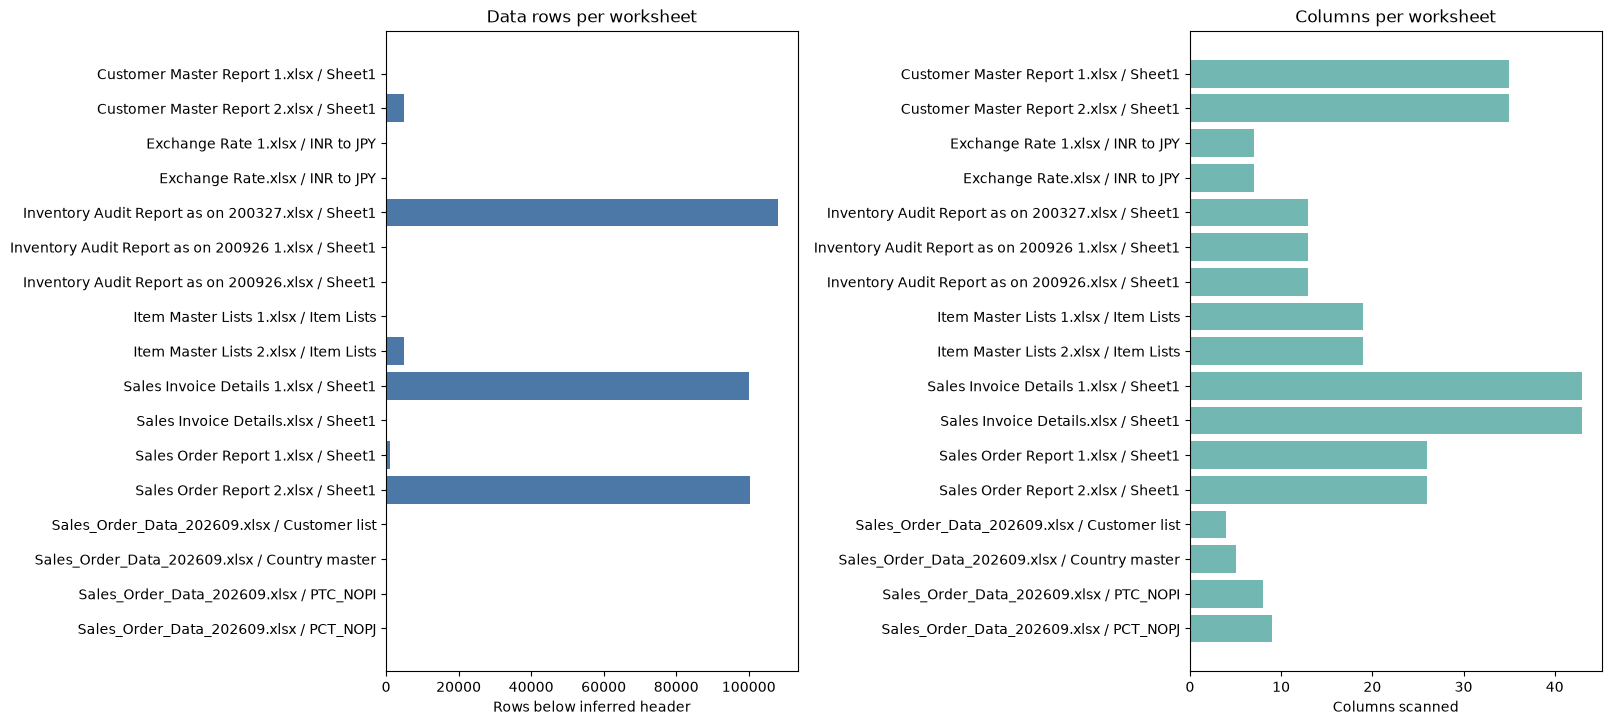

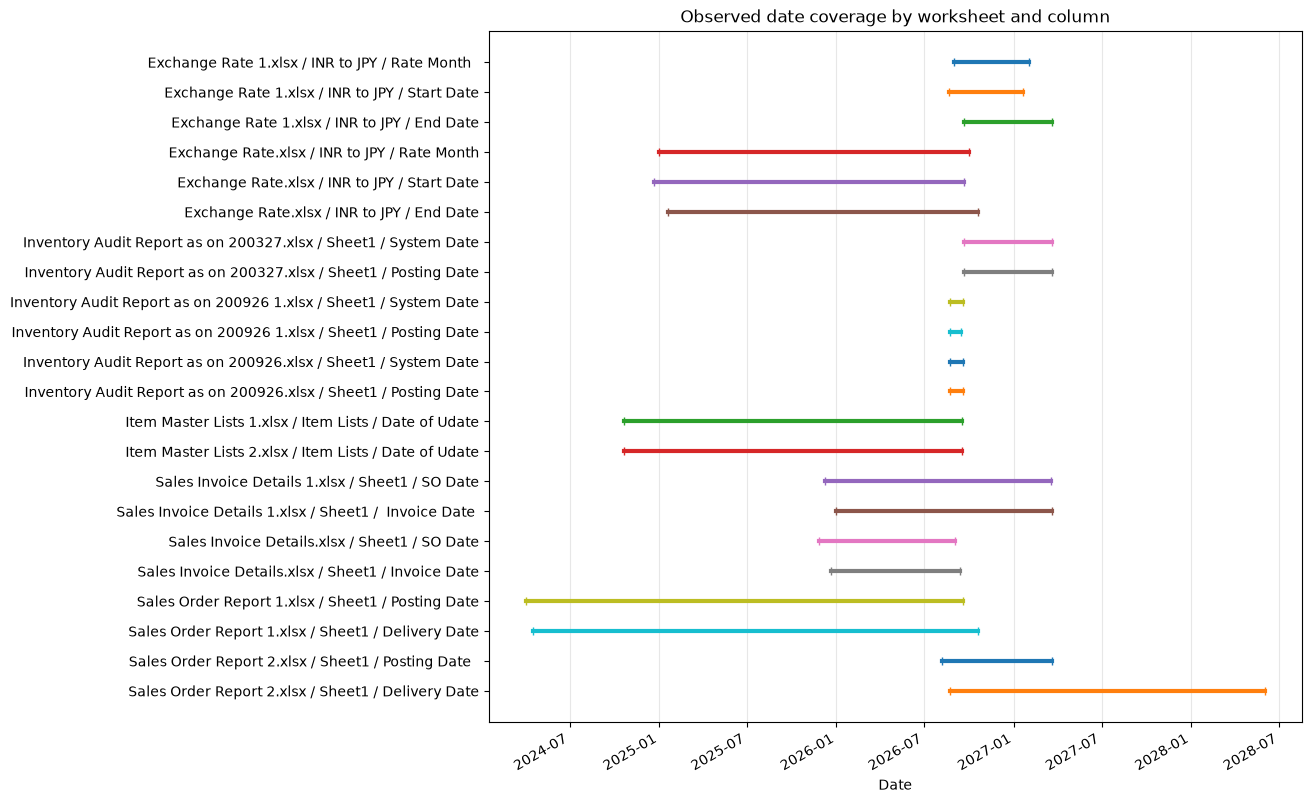

Reports saved to D:\Aroha_Files\NOP_Project\reports\data_inventory


In [7]:
successful = sheets_df[sheets_df['status'] == 'success'].copy() if not sheets_df.empty else pd.DataFrame()
if not successful.empty:
    labels = successful['file'].astype(str) + ' / ' + successful['worksheet'].astype(str)
    height = max(4, len(successful) * 0.42)
    fig, axes = plt.subplots(1, 2, figsize=(16, height), constrained_layout=True)
    axes[0].barh(labels, successful['data_rows_below_header'], color='#4c78a8')
    axes[0].set_title('Data rows per worksheet')
    axes[0].set_xlabel('Rows below inferred header')
    axes[0].invert_yaxis()
    axes[1].barh(labels, successful['worksheet_columns_scanned'], color='#72b7b2')
    axes[1].set_title('Columns per worksheet')
    axes[1].set_xlabel('Columns scanned')
    axes[1].invert_yaxis()
    fig.savefig(REPORTS / 'worksheet_structure.png', dpi=160, bbox_inches='tight')
    plt.show()

if not dates_df.empty:
    coverage = dates_df.dropna(subset=['min_date', 'max_date']).copy()
    if not coverage.empty:
        coverage['label'] = coverage['file'].astype(str) + ' / ' + coverage['worksheet'].astype(str) + ' / ' + coverage['column_name'].astype(str)
        fig, ax = plt.subplots(figsize=(13, max(4, len(coverage) * 0.36)), constrained_layout=True)
        for i, item in enumerate(coverage.itertuples()):
            ax.plot([item.min_date, item.max_date], [i, i], marker='|', linewidth=3)
        ax.set_yticks(range(len(coverage)), coverage['label'])
        ax.invert_yaxis()
        ax.set_title('Observed date coverage by worksheet and column')
        ax.set_xlabel('Date')
        ax.grid(axis='x', alpha=0.3)
        fig.autofmt_xdate()
        fig.savefig(REPORTS / 'date_coverage.png', dpi=160, bbox_inches='tight')
        plt.show()

print(f'Reports saved to {REPORTS}')